# eiskit tutorial – comparing materials by EIS
Complete workflow: load spectra of several samples, check them, fit equivalent circuits (robustly), search the
literature circuits, compute the DRT and export publication figures and tables.

The example file `example_materials.xlsx` (created by `make_example_data.py`) holds five catalysts measured at one
potential. **For your own data change `DATA_PATH` below** – or paste data in section 1b.

*Prefer clicking to coding? Run `python -m eiskit app` (or double-click `eiskit/app/eiskit_app.html`).*

In [1]:
import eiskit as ek
import matplotlib.pyplot as plt
%matplotlib inline
DATA_PATH = "example_materials.xlsx"      # <<< your .xlsx / .csv / .txt file
print("eiskit", ek.__version__)

eiskit 2.0.0


## 1a. Load a file
Each three-column block (frequency, Z′, Z″ or −Z″) is one sample; its name is taken from the cell above the block.

In [2]:
data = ek.read_spectra(DATA_PATH)
for name, sp in data.items():
    print(sp)

Spectrum('NF/Ni(OH)2', 61 points, 0.1–1e+05 Hz)
Spectrum('NF/Ni3N', 61 points, 0.1–1e+05 Hz)
Spectrum('NF/Ni3N@PA', 61 points, 0.1–1e+05 Hz)
Spectrum('NF/Ni3N@NiFe-PA', 61 points, 0.1–1e+05 Hz)
Spectrum('NF/NiFe-PA', 61 points, 0.1–1e+05 Hz)


## 1b. …or paste data
Copy three columns from Excel/Origin/your instrument and paste them between the quotes. Separate columns also work (`ek.from_columns`), and `ek.prompt_spectrum()` asks for the data interactively.

In [3]:
pasted = """Frequency (Hz)	Z' (Ohm)	-Z'' (Ohm)
100000	1.02	0.02
10000	1.05	0.12
1000	1.60	1.10
100	4.80	2.30
10	6.10	0.60
1	6.20	0.07
0.1	6.21	0.01"""
extra = ek.from_text(pasted, "pasted example")
print(extra)
# data["My sample"] = extra            # add it to the comparison
# data["Typed in"] = ek.prompt_spectrum()

Spectrum('pasted example', 7 points, 0.1–1e+05 Hz)


## 2. Kramers–Kronig check
The test is robust: instead of failing as a whole it lists the frequencies that violate KK (glitches, top of the instrument range).

In [4]:
for name, sp in data.items():
    print(f"{name:<18}", ek.lin_kk(sp))

NF/Ni(OH)2         KKResult(CHECK: RMS 0.84 %, max 5.55 %, M=25, mu=0.51, 2 point(s) > 2 % at 20–631 Hz)


NF/Ni3N            KKResult(CHECK: RMS 0.94 %, max 6.61 %, M=26, mu=0.43, 2 point(s) > 2 % at 20–631 Hz)
NF/Ni3N@PA         KKResult(CHECK: RMS 0.90 %, max 6.53 %, M=19, mu=0.83, 2 point(s) > 2 % at 20–631 Hz)


NF/Ni3N@NiFe-PA    KKResult(CHECK: RMS 0.80 %, max 6.21 %, M=17, mu=0.74, 2 point(s) > 2 % at 20–631 Hz)


NF/NiFe-PA         KKResult(CHECK: RMS 0.89 %, max 7.29 %, M=23, mu=0.67, 2 point(s) > 2 % at 20–631 Hz)


## 3. Fit a circuit – any notation
The interpretation is printed so you can check it. The fit is robust: off-trend points are down-weighted (shown hollow), not deleted.

In [5]:
for text in ["R-p(R,CPE)", "Rs-p(Rct,CPEdl)", "(R)p(CPE-Ws)", "R(QR)(QR)", "L-R-(R||Q)"]:
    c = ek.Circuit(text)
    print(f"{text:<18} -> {c.string:<24} reads as  {c.explain()}")

R-p(R,CPE)         -> R0-p(R1,CPE1)            reads as  R0 + [R1 ∥ CPE1]
Rs-p(Rct,CPEdl)    -> Rs-p(Rct,CPEdl)          reads as  Rs + [Rct ∥ CPEdl]
(R)p(CPE-Ws)       -> p(R0,CPE1-Ws1)           reads as  [R0 ∥ (CPE1 + Ws1)]
R(QR)(QR)          -> R0-p(CPE1,R1)-p(CPE2,R2) reads as  R0 + [CPE1 ∥ R1] + [CPE2 ∥ R2]
L-R-(R||Q)         -> L1-R0-p(R1,CPE1)         reads as  L1 + R0 + [R1 ∥ CPE1]


NF/Ni3N: L1-Rs-p(Rct,CPEdl)   [L1 + Rs + [Rct ∥ CPEdl]]
RMS residual 0.417 % of |Z|, chi2 0.00205, reduced chi2 1.81e-05, R2 0.99990, AICc -1282.9, valid
2 point(s) deviate from the trend and were down-weighted (robust fit)
  L1              2.989e-07 ± 4.36e-09   (   1.5 %) H
  Rs                 1.0498 ± 0.000957   (   0.1 %) Ohm
  Rct                8.2068 ± 0.0101     (   0.1 %) Ohm
  CPEdl_Q         0.0030064 ± 1.69e-05   (   0.6 %) S*s^n
  CPEdl_n           0.84992 ± 0.000956   (   0.1 %) -


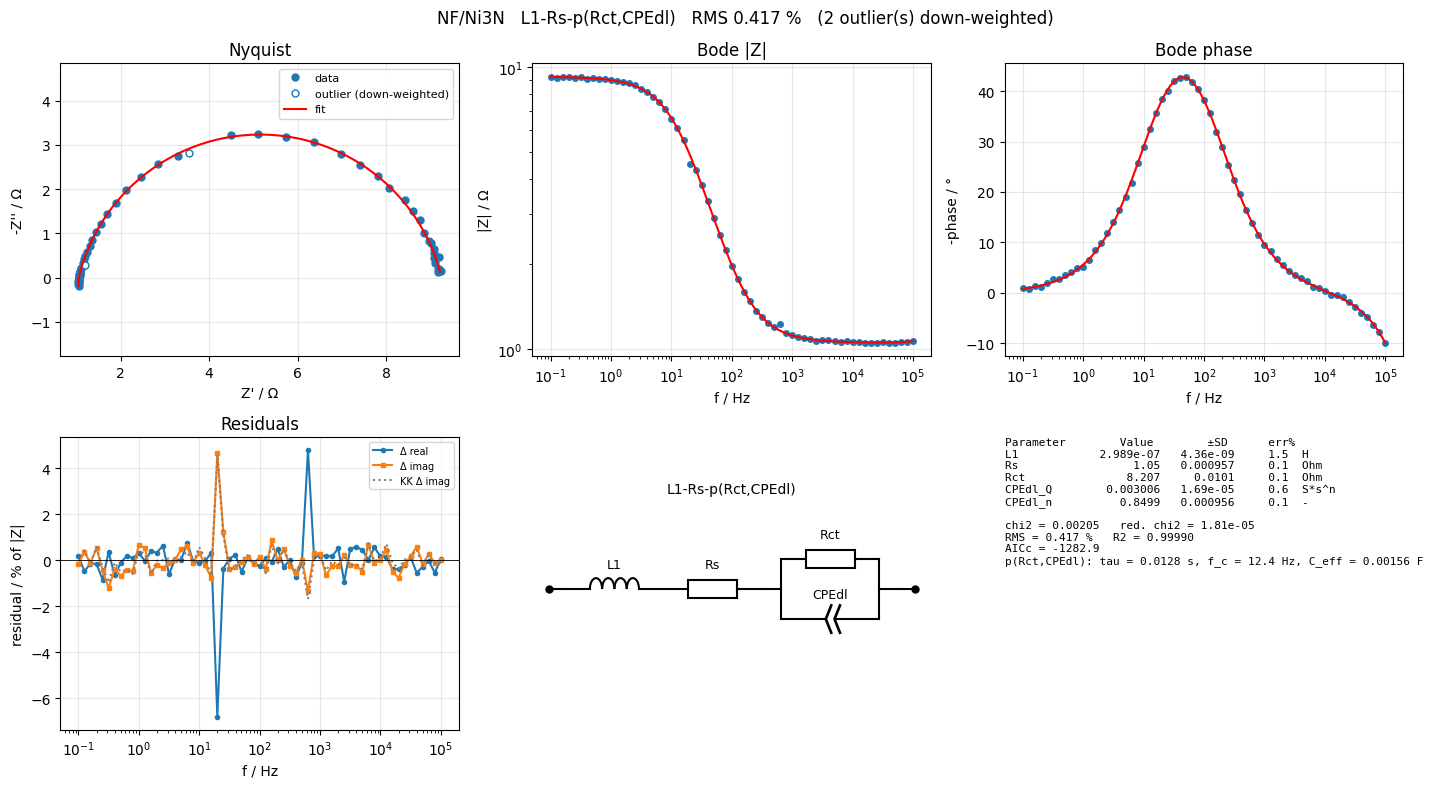

,value,std_error,rel_error_pct,ci95_low,ci95_high,unit
L1,2.988974e-07,4.364053e-09,1.460051,2.903438e-07,3.074509e-07,H
Rs,1.049785e+00,9.569897e-04,0.091160,1.047910e+00,1.051661e+00,Ohm
Rct,8.206774e+00,1.012933e-02,0.123426,8.186921e+00,8.226627e+00,Ohm
CPEdl_Q,3.006372e-03,1.688286e-05,0.561569,2.973281e-03,3.039462e-03,S*s^n
CPEdl_n,8.499219e-01,9.555122e-04,0.112424,8.480491e-01,8.517947e-01,-


In [6]:
r = ek.fit(data["NF/Ni3N"], "L-Rs-p(Rct,CPEdl)")
print(r.summary())
ek.plot_fit(r, data["NF/Ni3N"], ek.lin_kk(data["NF/Ni3N"])); plt.show()
r.table()

## 4. Search the literature circuits (64)
`search` ranks every circuit for one sample; `fit_all(..., \"search-common\")` finds the single circuit that works best for all samples, so that parameters can be compared.

In [7]:
s = ek.search(data["NF/Ni3N"])
display(s.ranking.head(8)[["circuit", "description", "k", "RMS_%", "AICc", "valid"]])

screening 64 circuits on 1 core(s) ...


done: 64 circuits in 19.6 s; best L0-R0-p(R1,CPE1) (RMS 0.417 %)


,circuit,description,k,RMS_%,AICc,valid
rank,,,,,,
1,"L0-R0-p(R1,CPE1)",Randles with cable inductance – high-frequency...,5,0.416725,-1282.862299,True
2,"Ls0-R0-p(R1,CPE1)-p(R2,CPE2)",Two arcs with signed HF inductance – instrumen...,8,0.409901,-1279.973038,True
3,"R0-p(CPE1,R1-p(R2,CPE2))",Coated metal / porous film (nested) – coatings...,7,0.639666,-1035.644963,True
4,"R0-p(R1,CPE1)",Simplified Randles (CPE) – electrocatalysis (H...,4,0.663196,-1034.893749,True
5,"R0-p(CPE1,R1,R2-p(CPE2,R3))",Surface-state model (CPE) – photoelectrochemistry,8,0.639666,-1033.295842,True
6,"R0-p(R1,C1)-p(R2,C2)-p(R3,C3)","Brick-layer model – ceramics, solid electrolyt...",7,1.891675,-905.471122,True
7,"R0-p(R1-Ws1,C1)","Randles, finite-length diffusion (ideal C) – t...",5,3.346497,-818.413270,True
8,"R0-p(C1,R1-p(R2,C2))",Coated metal (ideal capacitances) – coatings,5,3.448240,-811.105472,True


In [8]:
res = ek.fit_all(data, "search-common")
res

searching circuits for NF/Ni(OH)2 ...


searching circuits for NF/Ni3N ...


searching circuits for NF/Ni3N@PA ...


searching circuits for NF/Ni3N@NiFe-PA ...


searching circuits for NF/NiFe-PA ...


...

NF/Ni3N                L0-R0-p(R1,CPE1)                 RMS 0.417 %  valid


NF/Ni3N@PA             L0-R0-p(R1,CPE1)                 RMS 0.410 %  valid


NF/Ni3N@NiFe-PA        L0-R0-p(R1,CPE1)                 RMS 0.405 %  valid


NF/NiFe-PA             L0-R0-p(R1,CPE1)                 RMS 0.372 %  valid


Results
  NF/Ni(OH)2             L0-R0-p(R1,CPE1)                 RMS 0.376 %  valid  (2 outlier(s))
  NF/Ni3N                L0-R0-p(R1,CPE1)                 RMS 0.417 %  valid  (2 outlier(s))
  NF/Ni3N@PA             L0-R0-p(R1,CPE1)                 RMS 0.410 %  valid  (2 outlier(s))
  NF/Ni3N@NiFe-PA        L0-R0-p(R1,CPE1)                 RMS 0.405 %  valid  (2 outlier(s))
  NF/NiFe-PA             L0-R0-p(R1,CPE1)                 RMS 0.372 %  valid  (2 outlier(s))

## 5. Comparison figures (standard literature style)

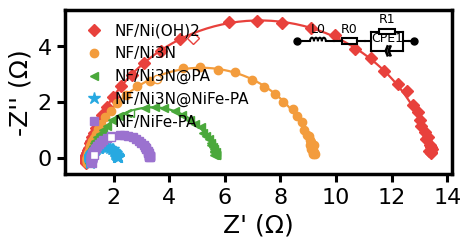

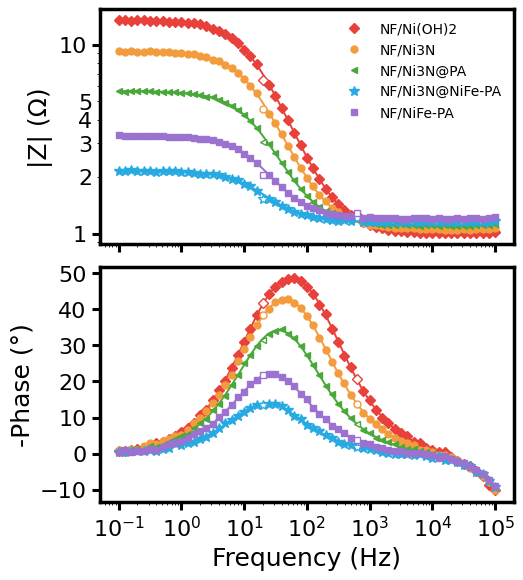

In [9]:
circ = res.fits[next(iter(res.fits))].circuit.string
ek.plot_nyquist(res, circuit_inset=circ); plt.show()
ek.plot_bode(res); plt.show()

## 6. Distribution of relaxation times

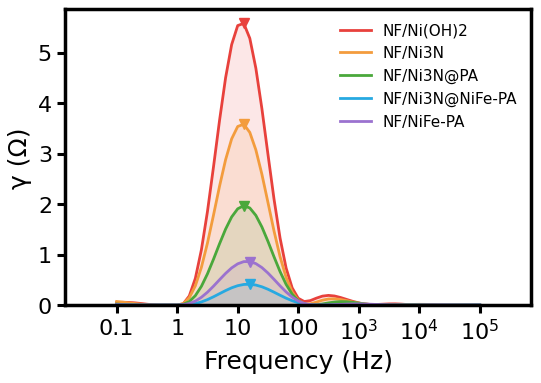

NF/Ni(OH)2         R_inf 0.987 Ohm, R_pol 12.463 Ohm, major peaks at 12.6 Hz
NF/Ni3N            R_inf 1.048 Ohm, R_pol 8.285 Ohm, major peaks at 12.6 Hz
NF/Ni3N@PA         R_inf 1.102 Ohm, R_pol 4.625 Ohm, major peaks at 12.6 Hz
NF/Ni3N@NiFe-PA    R_inf 1.143 Ohm, R_pol 1.022 Ohm, major peaks at 15.8 Hz
NF/NiFe-PA         R_inf 1.200 Ohm, R_pol 2.116 Ohm, major peaks at 15.8 Hz


In [10]:
drts = {n: ek.drt(sp) for n, sp in data.items()}
ek.plot_drt(drts); plt.show()
for n, d in drts.items():
    print(f"{n:<18} R_inf {d.R_inf:.3f} Ohm, R_pol {d.R_pol:.3f} Ohm, major peaks at",
          ", ".join(f"{x:.3g} Hz" for x in d.peaks[d.peaks.major].f_Hz))

## 7. Tables and export

In [11]:
display(res.comparison_table())
import os; os.makedirs("results", exist_ok=True)
res.to_excel("results/EIS_results.xlsx")
try:
    res.to_docx("results/EIS_tables.docx")
except ImportError:
    print("pip install python-docx for the Word report")
ek.save_figure(ek.plot_nyquist(res, circuit_inset=circ), "results/nyquist")       # SVG + 600 dpi TIFF
ek.save_figure(ek.plot_bode(res), "results/bode")
ek.save_figure(ek.plot_drt(drts), "results/drt")
plt.close("all")
print(sorted(os.listdir("results")))

,Element,NF/Ni(OH)2,NF/Ni3N,NF/Ni3N@PA,NF/Ni3N@NiFe-PA,NF/NiFe-PA
0,L_0 (H),(3.016 ± 0.038) × 10^-7,(2.989 ± 0.044) × 10^-7,(2.987 ± 0.045) × 10^-7,(3.036 ± 0.046) × 10^-7,(3.008 ± 0.044) × 10^-7
1,R_s (Ω),1.00001 ± 0.00085,1.04979 ± 0.00096,1.09983 ± 0.00096,1.14965 ± 0.00094,1.20046 ± 0.00091
2,R_1 (Ω),12.511 ± 0.013,8.207 ± 0.010,4.5986 ± 0.0063,1.0016 ± 0.0027,2.1022 ± 0.0035
3,CPE1-T (S·s^n),0.0019925 ± 0.0000088,0.003006 ± 0.000017,0.005006 ± 0.000035,0.02011 ± 0.00033,0.009965 ± 0.000096
4,CPE1-P,0.85065 ± 0.00072,0.84992 ± 0.00096,0.8501 ± 0.0012,0.8495 ± 0.0032,0.8506 ± 0.0018
5,χ^2,1.7 × 10^-3,2.0 × 10^-3,2.0 × 10^-3,1.9 × 10^-3,1.6 × 10^-3


['EIS_results.xlsx', 'EIS_tables.docx', 'bode.svg', 'bode.tiff', 'drt.svg', 'drt.tiff', 'nyquist.svg', 'nyquist.tiff']
